## Ornek 2

This script implements the example problem given in the text book, under the section 5.1.2. The example details the phase response of a LTI system and its group delay. In this script, we will simulate an input signal which consists of three sinusoidal components with different frequencies. The signal then, is applied to the LTI system with the function SystemFunction. This system is provided for you as a user defined python function, thus, you need to import it accordingly.  


For the moment, the contents of the SystemFunction is not important for you and we do not want you to understand it. You can think of it as a black-box system.  


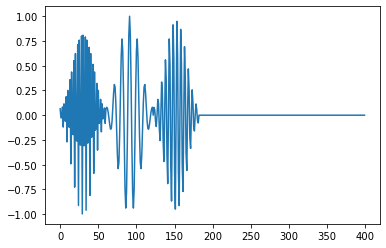

In [188]:
# As usual, we begin with importing necessary libraries and functions  
import numpy as np # for using basic array functions  
import matplotlib.pyplot as plt # for this example, it may not be necessary  
# the main package for signal processing is called "scipy" and we will use \leftrightarrow"signal" sub-package  
import scipy.signal as sgnl  
from scipy.fftpack import fft, ifft  
# alternative syntax: from scipy import signal as sgnl   
# WE NEED TO IMPORT THE CUSTOM (USER DEFINED) FUNCTION AS WELL, IN ORDER TO USE  
import SystemFunction  
# Generate the individual components and the input signal  
N = 400 # total number of samples in the input signal  
M =60 # size of the window function (and sample length of the frequency
n = np.arange(0, M+1, 1) # index vector of M+1 points  
wn = 0.54-0.46*np.cos(2*np.pi*n/M) # window function (Hamming window)  
# the components  
x1 = wn*np.cos(0.2*np.pi*n) # component with w1 = 0.2*pi frequency  
x2 = wn*np.cos(0.4*np.pi*n - np.pi/2) # component with w1 = 0.4*pi frequency  
x3 = wn*np.cos(0.8*np.pi*n - np.pi/5) # component with w1 = 0.8*pi frequency  
xn = np.concatenate((x3, x1, x2, np.zeros(N-3*len(n))), axis=None)  
plt.figure()
plt.plot(xn)
plt.show()


We created a signal with three frequency components. We need to calculate the frequency response of the signal, because we will apply it to the system in the frequency domain. Since our system will be defined in the interval of $[-\pi, \pi] \mathrm{rad} / \mathrm{samples}$, the Fourier transform of the signal must be in that interval, too.  


Note that, fft calculates the Fourier transform in $[0 , 2 \pi]$. Thus we need to shift it to the correct interval by the following code:  


In [189]:
# Calculate the Fourier transform of in  
w = np.linspace(-np.pi, np.pi, N)  
Xw = fft(xn)  
Xw_shifted = np.fft.fftshift(Xw)

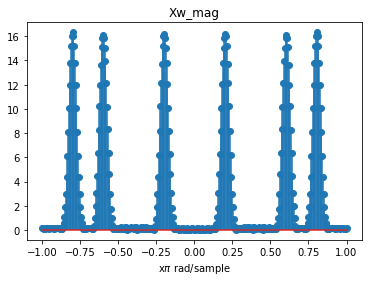

In [190]:
#From video
Xw_mag = abs(Xw)
plt.figure()
plt.stem(w/np.pi, Xw_mag)
plt.xlabel('x$\pi$ rad/sample')
plt.title("Xw_mag")
plt.show()

The system is defined by the SystemFunction and its magnitude and phase plots are shown in the following figure:  


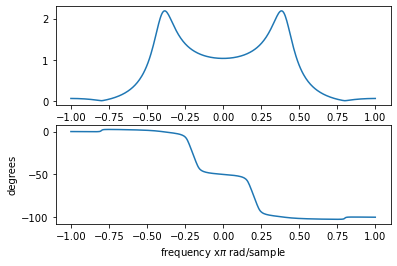

In [191]:
Hw, polezz, zerozz, K = SystemFunction.SystemFunction(w)  
Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
fig, (ax1, ax2) = plt.subplots(2)  
ax1.plot(w/np.pi, Hw_mag)  
ax2.plot(w/np.pi, Hw_phs), plt.ylabel('degrees')  
plt.xlabel('frequency x$\pi$ rad/sample')  
plt.show()


By using the phase response, we calculate its group delay as follows.  
Note the term $\frac{N}{2 \pi}$ is necessary, when we calculate the group delay manually, to obtain correct unit of measurements. Otherwise, it is impossible to interpret the result. 

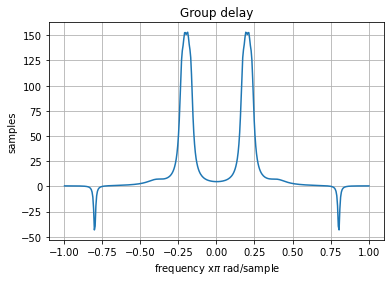

In [192]:
# calculate the group delay of the system:  
tau_w = -np.diff(Hw_phs)*(N/(2*np.pi))  #!dont forget to scale with (N/(2*np.pi)) 
plt.figure()  
plt.title("Group delay")
plt.plot(w[1::]/np.pi, tau_w)  
plt.ylabel('samples'), plt.xlabel('frequency x$\pi$ rad/sample')  
plt.grid()
plt.show()

Now, we will appy the input signal to the system in the frequency domain by multiplying the Fourier transforms of both the signal and the system impulse response. After that, we will take the inverse Fourier transform of the output signal and compare it with the input signal. Our aim is to confirm the effect of the group delay by simulation.  
  
Please note how we perform the inverse fft by first calculating inverse fftshift and then ifft.

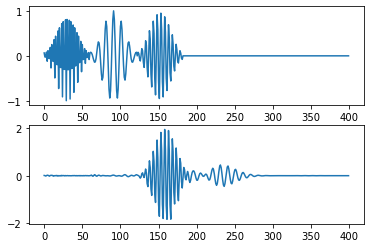

In [193]:
Yw_shifted = Hw * Xw_shifted # we multiply the frequency response of   the system with the **shifted** Fourier transform of the signal  
Yw = np.fft.ifftshift(Yw_shifted) # we shifted back to the 0-2*pi interval  
yn = np.real(ifft(Yw)) # we calculate the inverse fft and take  the real component (because of numerical consistency)  
fig, (ax1, ax2) = plt.subplots(2)  
ax1.plot(xn)  
ax2.plot(yn)
plt.show()

Now we by looking at the input signal, frequency response of the system, and the output signal, we can analyze the the effect of the group delay on the signal. As can be seen in the last figure, components with different frequencies shifted different amounts of samples. The component with the lowest frequency $(0.2 \pi \mathrm{rad} / \mathrm{samples})$ shifted 150 samples. The component with $0.4 \pi \mathrm{rad} / \mathrm{samples}$ shifted approx. 4 samples. Since the system suppressed the component with the highes frequency, it is not our concern anymore.  
  
The obtained result, however, is problematic in most real-world (especially in real-time) applications. Because of the system, the signal is found to be distorted at the output. Consider the following analogy: you are playing a specific music part. You are playing several tones (input signal), however your instrument (i.e. the system) does not play the tunes in the correct order for some reason. Thus, it produces some nonsensical signal, which would be humiliating in front of an audience.

## Ornek3

([<matplotlib.lines.Line2D at 0x7fc9c11e5ac0>],
 Text(0, 0.5, 'phase (rad)'),
 Text(0.5, 0, 'frequency rad/sample'))

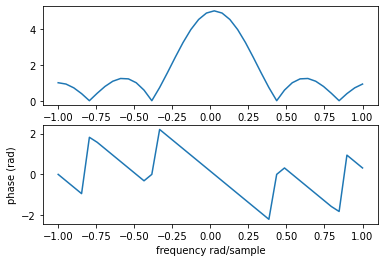

In [194]:
# As usual, we begin with importing necessary libraries and functions  
import numpy as np # for using basic array functions  
import matplotlib.pyplot as plt # for this example, it may not be necessary  
# the main package for signal processing is called "scipy" and we will use u "signal" sub-package  
import scipy.signal as sgnl  
from scipy.fftpack import fft, ifft  
# alternative syntax: from scipy import signal as sgnl  
N = 40
hn = np.ones(5)  
Hw = np.fft.fftshift(fft(hn, N))  
w = np.linspace(-np.pi, np.pi,N)  
Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
fig, (ax1, ax2) = plt.subplots(2)  
ax1.plot(w/np.pi, Hw_mag)  
ax2.plot(w/np.pi, Hw_phs), plt.ylabel('phase (rad)'), plt.xlabel('frequency rad/sample')



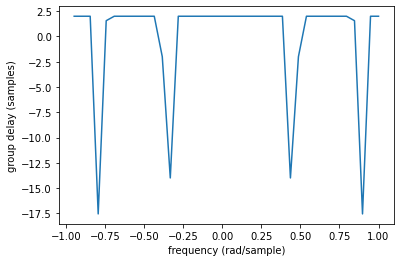

In [195]:
tau_w = -np.diff(Hw_phs)*(N/(2*np.pi))  
plt.figure()  
plt.plot(w[1::]/np.pi, tau_w)  
plt.xlabel('frequency (rad/sample)')  
plt.ylabel('group delay (samples)')
plt.show()

Now, we will simulate a sinusoidal signal and apply it to the input of the system defined above. Then by comparing input and the output, we will observe and confirm the effects of the group delay.  


In [196]:
n = np.arange(0, N, 1) # first create the index vector at N points  
w0 = 0.1*np.pi # frequency of the input signal  
xn = np.cos(w0*n) # create the input signal at w0  
Xw = np.fft.fftshift(fft(xn, N)) # compute the frequency response (in the U<[-pi pi] interval)  
Yw_shifted = Hw * Xw # compute the fft of the output signal  
Yw = np.fft.ifftshift(Yw_shifted) # we shifted back to the 0-2*pi interval  
yn = np.real(ifft(Yw))

Now that we found the output signal in the time domain, we will compare it to the input and interpret the results.  


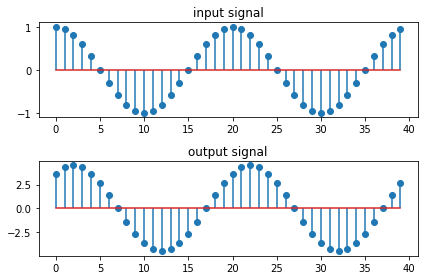

In [197]:
fig, (ax1, ax2) = plt.subplots(2)  
ax1.stem(n, xn), ax1.title.set_text('input signal')  
ax2.stem(n, yn), ax2.title.set_text('output signal')
plt.tight_layout()
plt.show()

Now, by looking at the first peaks, we can confirm that, as we have predicted from the group delay, the output signal shifted exactly 2 samples with respect to the input.

# Ornek 4

In [198]:

# As usual, we begin with importing necessary libraries and functions  
import numpy as np # for using basic array functions  
import matplotlib.pyplot as plt # for this example, it may not be necessary  
# the main package for signal processing is called "scipy" and we will use "signal" sub-package  
import scipy.signal as sgnl  
from scipy.fftpack import fft, ifft  
# alternative syntax: from scipy import signal as sgnl  
# to read .csv data file  
from scipy.io import loadmat  



We will use scipy.io library for loading .mat files. The following piece of code shows how to access the filter coefficients properly. Note that, if you import an IIR filter, both numerator and denominator coefficients exist. But, if you import an FIR filter, only numerator coefficients exist.  



In [199]:
# importing an IIR filter  
filter_data = loadmat('butterworth.mat') # load the filter obtained from  pyfda  
Coeffs = filter_data['ba'].astype(float) # get the coefficients and  <convert them to float (from string)  
#print(Coeffs)
b = Coeffs[:,0] # first column is b  
a = Coeffs[:,1] # second column is a (only if the filter is IIR)  


Now that we obtained the coefficients, we can use them for any purpose. We will demonstrate frequency domain plots and the impulse response for now.  


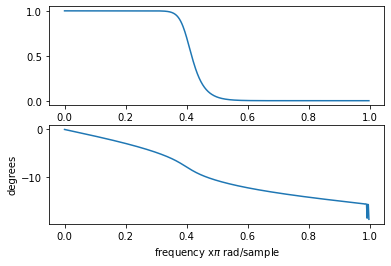

In [200]:

w, Hw = sgnl.freqz(b,a)  
Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
fig, (ax1, ax2) = plt.subplots(2)  
ax1.plot(w/np.pi, Hw_mag)  
ax2.plot(w/np.pi, Hw_phs), plt.ylabel('degrees')  
plt.xlabel('frequency x$\pi$ rad/sample')
plt.show()


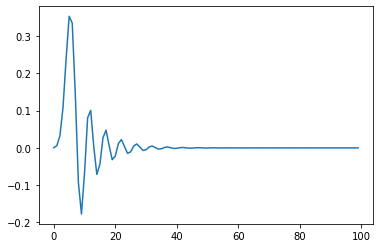

In [201]:
n, hn = sgnl.dimpulse((b,a,1), n=100)  
# compute the impulse response for 100 points  
plt.figure()  
plt.plot(n, np.squeeze(hn))  
plt.show()

Now we will use this filter with an arbitrary signal to filter out a frequency component. We will use the same signal as in the Ornek2. We will use lfilter function (recall from the z-transform prelab) for filtering using the coefficients.  


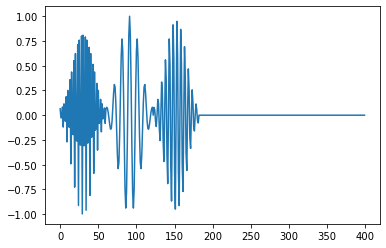

In [202]:
# Generate the individual components and the input signal  
N = 400 # total number of samples in the input signal  
M = 60 # size of the window function (and sample length of the frequency  components)  
n1 = np.arange(0, M+1, 1) # index vector of M+1 points  
wn = 0.54 - 0.46*np.cos(2*np.pi*n1/M) # window function (Hamming window)  
# the components  
x1 = wn*np.cos(0.2*np.pi*n1) # component with w1 = 0.2*pi  frequency  
x2 = wn*np.cos(0.4*np.pi*n1 - np.pi/2) # component with w1 = 0.4*pi  frequency  
x3 = wn*np.cos(0.8*np.pi*n1 - np.pi/5) # component with w1 = 0.8*pi  frequency  
xn = np.concatenate((x3, x1, x2, np.zeros(N-3*len(n1))), axis=None)  
plt.figure()  
plt.plot(xn)  


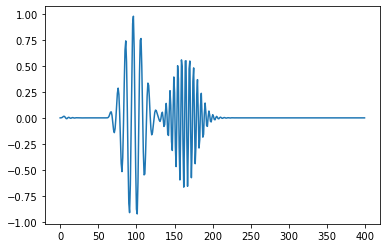

In [203]:
yn = sgnl.lfilter(b,a,xn) 
plt.figure()
plt.plot(yn)
plt.show()

# Ödev 6

## 1)
Pyfda kullanarak, farklı filtreler tasarlayınız. Filtrelerden biri bant geçiren, diğeri alçak geçiren olacak şekilde en az iki farklı yöntemle FIR filtre tasarlayınız. Kesim frekanslarını, filtrelerin bant genişlikleri yaklaşık 0.3𝜋 olacak şekilde istediğiniz gibi seçebilirsiniz. Filtre derecesini istenen kesim frekanslarında en az 3 dB zayıflama olacak şekilde belirleyiniz. Filtrelerin genlik, faz cevaplarını ve grup gecikmelerini çizdirip inceleyiniz. Gözlemlerinizi anlatınız.

### Bant geçiren FIR filtre tasarımı (Blackman)
(0.3 * pi , 0.6 * pi) arası geçirecek şekilde tasarlanmıştır
Kullanılan yöntem Blackman derecesi N = 40 

In [244]:

# As usual, we begin with importing necessary libraries and functions  
import numpy as np # for using basic array functions  
import matplotlib.pyplot as plt # for this example, it may not be necessary  
# the main package for signal processing is called "scipy" and we will use "signal" sub-package  
import scipy.signal as sgnl  
from scipy.fftpack import fft, ifft  
# alternative syntax: from scipy import signal as sgnl  
# to read .csv data file  
from scipy.io import loadmat  


In [245]:
# importing an IIR filter  
filter_data = loadmat('blackman_bandpass.mat') # load the filter obtained from  pyfda  
Coeffs = filter_data['ba'].astype(float) # get the coefficients and  <convert them to float (from string)  
#print(Coeffs)
b = Coeffs[:,0] # first column is b  
a = 1


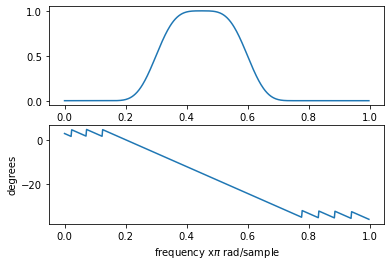

In [246]:

w, Hw = sgnl.freqz(b,a)  
Hw_mag = abs(Hw)  
N = len(Hw)*2

Hw_phs = np.unwrap(np.angle(Hw))  
fig, (ax1, ax2) = plt.subplots(2)  
ax1.plot(w/np.pi, Hw_mag)  
ax2.plot(w/np.pi, Hw_phs), plt.ylabel('degrees')  
plt.xlabel('frequency x$\pi$ rad/sample')
plt.show()


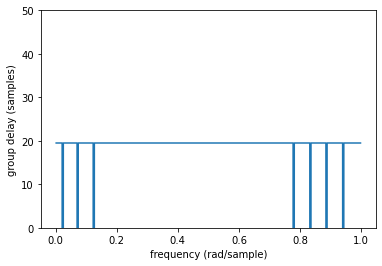

In [249]:
tau_w = -np.diff(Hw_phs)*(N/(2*np.pi))  
plt.figure()  
plt.ylim([0,50])
plt.plot(w[1::]/np.pi, tau_w)  
plt.xlabel('frequency (rad/sample)')  
plt.ylabel('group delay (samples)')
plt.show()

0.3*pi ve 0.6 *pi arası bant geçiren filtredir, 0.3 pi de -5.2 db azalmaya sahiptir. Fazı o bölgede lineardir. 0 ve 0.2 pi arası lineer değil ama çok önemi yok ünkü zaten o bölgede sinyal geçememektedir.

### Bant geçiren FIR filtre tasarımı (Barthann)
Geçirme frekansı (0.2 * pi, 0.5 * pi) arasındadır. Filtere derecesi 30 'dur.


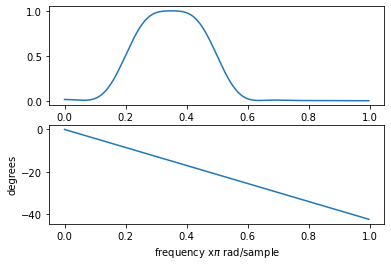

In [250]:

# As usual, we begin with importing necessary libraries and functions  
import numpy as np # for using basic array functions  
import matplotlib.pyplot as plt # for this example, it may not be necessary  
# the main package for signal processing is called "scipy" and we will use "signal" sub-package  
import scipy.signal as sgnl  
from scipy.fftpack import fft, ifft  
# alternative syntax: from scipy import signal as sgnl  
# to read .csv data file  
from scipy.io import loadmat  

# importing an IIR filter  
filter_data = loadmat('bandpass_barthann.mat') # load the filter obtained from  pyfda  
Coeffs = filter_data['ba'].astype(float) # get the coefficients and  <convert them to float (from string)  
#print(Coeffs)
b = Coeffs[:,0] # first column is b  
a = 1


w, Hw = sgnl.freqz(b,a)  
N = len(Hw)*2

Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
fig, (ax1, ax2) = plt.subplots(2)  
ax1.plot(w/np.pi, Hw_mag)  
ax2.plot(w/np.pi, Hw_phs), plt.ylabel('degrees')  
plt.xlabel('frequency x$\pi$ rad/sample')
plt.show()



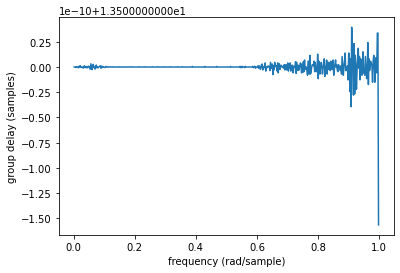

In [251]:
tau_w = -np.diff(Hw_phs)*(N/(2*np.pi))  
plt.figure()  
plt.plot(w[1::]/np.pi, tau_w)  
plt.xlabel('frequency (rad/sample)')  
plt.ylabel('group delay (samples)')
plt.show()

Grup gecikmesi olmamaktadır çünkü faz lineerdir. Faz lineer olduğundan sistem bozulmasızdır.

## Alçak geçiren Filtre tasarımı Hann (0.3*pi kesim frekansı)

0.3*pi kesim frekansı olarak seçildi hann filtresi, derecesi 40'tır

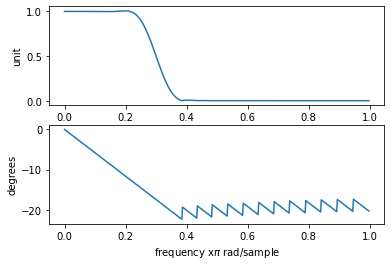

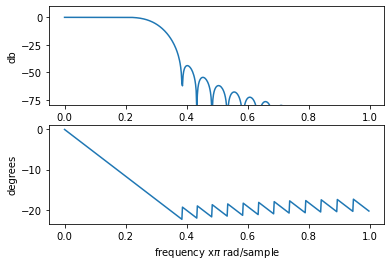

In [252]:

# As usual, we begin with importing necessary libraries and functions  
import numpy as np # for using basic array functions  
import matplotlib.pyplot as plt # for this example, it may not be necessary  
# the main package for signal processing is called "scipy" and we will use "signal" sub-package  
import scipy.signal as sgnl  
from scipy.fftpack import fft, ifft  
# alternative syntax: from scipy import signal as sgnl  
# to read .csv data file  
from scipy.io import loadmat  

# importing an IIR filter  
filter_data = loadmat('lowpass_hann.mat') # load the filter obtained from  pyfda  
Coeffs = filter_data['ba'].astype(float) # get the coefficients and  <convert them to float (from string)  
#print(Coeffs)
b = Coeffs[:,0] # first column is b  
a = 1


w, Hw = sgnl.freqz(b,a)  
N = len(Hw)*2
Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
plt.subplot(2,1,1)
plt.plot(w/np.pi, Hw_mag)  , plt.ylabel("unit")
plt.subplot(2,1,2)
plt.plot(w/np.pi, Hw_phs), plt.ylabel('degrees')  
plt.xlabel('frequency x$\pi$ rad/sample')
plt.show()



w, Hw = sgnl.freqz(b,a)  
Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
plt.subplot(2,1,1)
plt.plot(w/np.pi, 20*np.log10(Hw_mag))  , plt.ylabel("db")
plt.ylim([-80,10])
plt.subplot(2,1,2)
plt.plot(w/np.pi, Hw_phs), plt.ylabel('degrees')  
plt.xlabel('frequency x$\pi$ rad/sample')
plt.show()


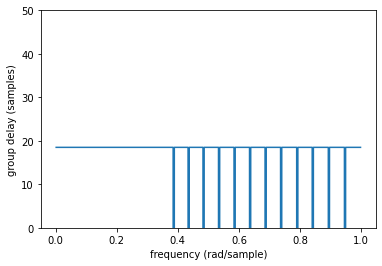

In [253]:
tau_w = -np.diff(Hw_phs)*(N/(2*np.pi))  
plt.figure()  
plt.ylim([0,50])
plt.plot(w[1::]/np.pi, tau_w)  
plt.xlabel('frequency (rad/sample)')  
plt.ylabel('group delay (samples)')
plt.show()

In [254]:
print(tau_w[2])

18.499999999999986


grup gecikme 18.5 örnek olarak gözükmektedir

## 2)
Pyfda kullanarak, farklı filtreler tasarlayınız. Filtrelerden biri yüksek geçiren, diğeri alçak geçiren olacak şekilde en az iki farklı yöntemle IIR filtre tasarlayınız. Kesim frekanslarını, filtrelerin bant genişlikleri yaklaşık 0.3𝜋 olacak şekilde istediğiniz gibi seçebilirsiniz. Filtre derecesini istenen kesim frekanslarında en az 3 dB zayıflama olacak şekilde belirleyiniz. Filtrelerin genlik, faz cevaplarını ve grup gecikmelerini çizdirip inceleyiniz. Gözlemlerinizi anlatınız.

### Butterwoth low pass IIR filter 
fc = 0.3*pi filter degree = 20

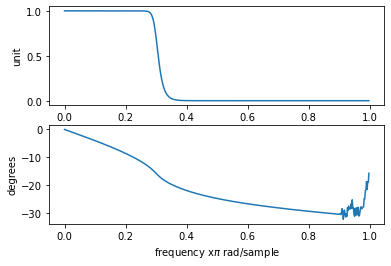

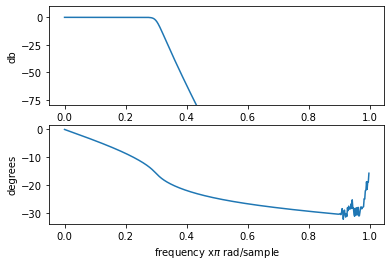

In [255]:

# As usual, we begin with importing necessary libraries and functions  
import numpy as np # for using basic array functions  
import matplotlib.pyplot as plt # for this example, it may not be necessary  
# the main package for signal processing is called "scipy" and we will use "signal" sub-package  
import scipy.signal as sgnl  
from scipy.fftpack import fft, ifft  
# alternative syntax: from scipy import signal as sgnl  
# to read .csv data file  
from scipy.io import loadmat  

# importing an IIR filter  
filter_data = loadmat('lowpass_butterworth.mat') # load the filter obtained from  pyfda  
Coeffs = filter_data['ba'].astype(float) # get the coefficients and  <convert them to float (from string)  
#print(Coeffs)
b = Coeffs[:,0] # first column is b  
a = Coeffs[:,1]


w, Hw = sgnl.freqz(b,a)  
N = len(Hw)*2 #! Hw nin 0 ve arası alındığından uzunluğu 2 ile çarpılır bu da fourierinin uzunluğuna karşı gelmektedir
Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
plt.subplot(2,1,1)
plt.plot(w/np.pi, Hw_mag)  , plt.ylabel("unit")
plt.subplot(2,1,2)
plt.plot(w/np.pi, Hw_phs), plt.ylabel('degrees')  
plt.xlabel('frequency x$\pi$ rad/sample')
plt.show()



w, Hw = sgnl.freqz(b,a)  
Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
plt.subplot(2,1,1)
plt.plot(w/np.pi, 20*np.log10(Hw_mag))  , plt.ylabel("db")
plt.ylim([-80,10])
plt.subplot(2,1,2)
plt.plot(w/np.pi, Hw_phs), plt.ylabel('degrees')  
plt.xlabel('frequency x$\pi$ rad/sample')
plt.show()


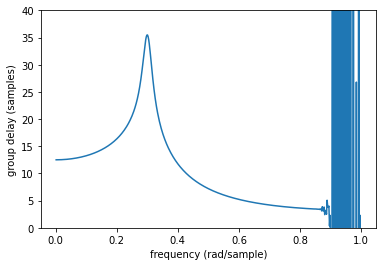

In [256]:
tau_w = -np.diff(Hw_phs)*(N/(2*np.pi))  
plt.figure()  
plt.plot(w[1::]/np.pi, tau_w)  
plt.ylim([0,40])
plt.xlabel('frequency (rad/sample)')  
plt.ylabel('group delay (samples)')
plt.show()


filte IIR dir ve linerar olmayan faza sahiptir. Her frekansta başka bir gecikme söz konusudur

### Bant geçiren IIR filtre tasarımı

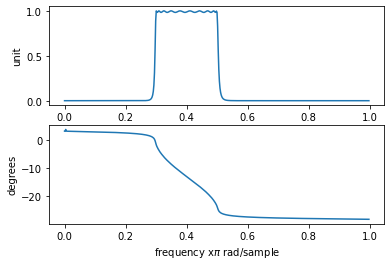

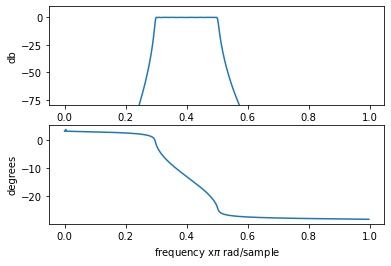

In [257]:

# As usual, we begin with importing necessary libraries and functions  
import numpy as np # for using basic array functions  
import matplotlib.pyplot as plt # for this example, it may not be necessary  
# the main package for signal processing is called "scipy" and we will use "signal" sub-package  
import scipy.signal as sgnl  
from scipy.fftpack import fft, ifft  
# alternative syntax: from scipy import signal as sgnl  
# to read .csv data file  
from scipy.io import loadmat  

# importing an IIR filter  
filter_data = loadmat('bandpass_chebyshev1.mat') # load the filter obtained from  pyfda  
Coeffs = filter_data['ba'].astype(float) # get the coefficients and  <convert them to float (from string)  
#print(Coeffs)
b = Coeffs[:,0] # first column is b  
a = Coeffs[:,1]


w, Hw = sgnl.freqz(b,a)  
N = len(Hw)*2
Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
plt.subplot(2,1,1)
plt.plot(w/np.pi, Hw_mag)  , plt.ylabel("unit")
plt.subplot(2,1,2)
plt.plot(w/np.pi, Hw_phs), plt.ylabel('degrees')  
plt.xlabel('frequency x$\pi$ rad/sample')
plt.show()



w, Hw = sgnl.freqz(b,a)  
Hw_mag = abs(Hw)  
Hw_phs = np.unwrap(np.angle(Hw))  
plt.subplot(2,1,1)
plt.plot(w/np.pi, 20*np.log10(Hw_mag))  , plt.ylabel("db")
plt.ylim([-80,10])
plt.subplot(2,1,2)
plt.plot(w/np.pi, Hw_phs), plt.ylabel('degrees')  
plt.xlabel('frequency x$\pi$ rad/sample')
plt.show()


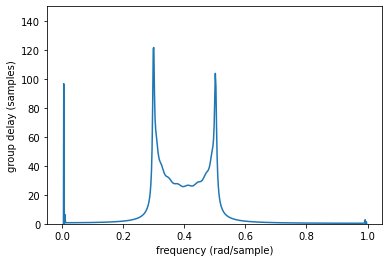

In [258]:
tau_w = -np.diff(Hw_phs)*(N/(2*np.pi))  
plt.figure()  
plt.plot(w[1::]/np.pi, tau_w)  
plt.ylim([0,150])
plt.xlabel('frequency (rad/sample)')  
plt.ylabel('group delay (samples)')
plt.show()
